In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
arquivo = raiz / "dados" / "dataset_industrial_cibersistemas_15k.csv"
dados = pd.read_csv(arquivo, parse_dates=["timestamp"])
print("Linhas e colunas:", dados.shape)
dados.head()


Linhas e colunas: (15000, 21)


,timestamp,lote_id,temperatura_solda_c,corrente_solda_a,tensao_solda_v,pressao_gas_bar,vibracao_mm_s,velocidade_linha_m_min,area_porosidade_px,temperatura_max_haz_c,...,tempo_parada_min,pecas_produzidas,pecas_boas,pecas_defeituosas,disponibilidade_pct,desempenho_pct,qualidade_pct,oee_pct,anomalia_isolamento,classe_falha
0,2026-10-01 06:00:00,LOTE_0001,216.83,164.06,23.99,4.48,1.18,12.58,1.20,224.34,...,0.0,25,24,1,100.0,100.0,96.0,96.0,0,Sem Falha
1,2026-10-01 06:01:00,LOTE_0001,219.37,161.51,24.55,4.23,0.89,12.47,83.10,242.44,...,1.0,0,0,0,0.0,0.0,100.0,0.0,1,Porosidade na Solda
2,2026-10-01 06:02:00,LOTE_0001,214.52,160.30,23.35,4.39,0.76,12.46,1.87,225.29,...,0.0,24,24,0,100.0,100.0,100.0,100.0,0,Sem Falha
3,2026-10-01 06:03:00,LOTE_0001,218.25,162.25,24.28,4.39,0.63,11.71,3.70,236.23,...,0.0,23,23,0,100.0,100.0,100.0,100.0,0,Sem Falha
4,2026-10-01 06:04:00,LOTE_0001,215.66,162.28,24.36,4.29,1.15,11.30,2.75,233.03,...,0.0,22,22,0,100.0,100.0,100.0,100.0,0,Sem Falha


In [2]:
dados = dados.sort_values("timestamp")
dados = dados.drop_duplicates()

# Preenche valores numéricos com a mediana da coluna.
colunas_numericas = dados.select_dtypes(include="number").columns
dados[colunas_numericas] = dados[colunas_numericas].fillna(dados[colunas_numericas].median())

# Preenche texto vazio com o valor mais frequente.
colunas_texto = dados.select_dtypes(include="object").columns
for coluna in colunas_texto:
    dados[coluna] = dados[coluna].fillna(dados[coluna].mode()[0])

print("Valores ausentes após tratamento:", dados.isna().sum().sum())
print("Duplicatas após tratamento:", dados.duplicated().sum())
print("Período:", dados.timestamp.min(), "a", dados.timestamp.max())


Valores ausentes após tratamento: 0
Duplicatas após tratamento: 0
Período: 2026-10-01 06:00:00 a 2026-10-11 15:59:00


In [3]:
# Audita zeros antes de qualquer substituição.
colunas_numericas = dados.select_dtypes(include="number").columns
zeros_por_coluna = dados[colunas_numericas].eq(0).sum()
zeros_por_coluna[zeros_por_coluna > 0].sort_values(ascending=False).to_frame("quantidade_de_zeros")


,quantidade_de_zeros
tempo_parada_min,14522
anomalia_isolamento,12556
pecas_defeituosas,10510
pecas_produzidas,76
pecas_boas,76
disponibilidade_pct,76
desempenho_pct,76
oee_pct,76
area_porosidade_px,11


In [4]:
# Salva os dados tratados para os scripts .py.
dados.to_csv(raiz / "dados" / "dados_tratados.csv", index=False)
print("Arquivo dados_tratados.csv salvo.")


Arquivo dados_tratados.csv salvo.


In [5]:
dados.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,15000,NaN,NaN,NaN,2026-10-06 10:59:30,2026-10-01 06:00:00,2026-10-03 20:29:45,2026-10-06 10:59:30,2026-10-09 01:29:15,2026-10-11 15:59:00,NaN
lote_id,15000,150,LOTE_0001,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura_solda_c,15000.0,NaN,NaN,NaN,214.672338,197.4,211.63,214.69,217.68,229.62,4.526752
corrente_solda_a,15000.0,NaN,NaN,NaN,160.210645,144.86,157.85,160.2,162.47,175.5,3.540139
tensao_solda_v,15000.0,NaN,NaN,NaN,23.726402,21.0,23.29,23.72,24.16,26.6,0.652137
pressao_gas_bar,15000.0,NaN,NaN,NaN,4.510994,3.8,4.37,4.51,4.65,5.16,0.206297
vibracao_mm_s,15000.0,NaN,NaN,NaN,1.200891,0.02,1.0,1.2,1.4,2.33,0.297952
velocidade_linha_m_min,15000.0,NaN,NaN,NaN,12.003681,9.77,11.67,12.0,12.34,13.91,0.503894
area_porosidade_px,15000.0,NaN,NaN,NaN,7.581233,0.0,1.12,2.26,3.34,119.99,20.057206
temperatura_max_haz_c,15000.0,NaN,NaN,NaN,227.670084,205.19,222.3875,226.585,231.03,287.98,9.566165


In [6]:
contagem = dados.classe_falha.value_counts().to_frame("quantidade")
contagem["percentual"] = (contagem.quantidade / len(dados) * 100).round(2)
contagem


,quantidade,percentual
classe_falha,,
Sem Falha,13214,88.09
Porosidade na Solda,1263,8.42
Desvio Termico HAZ,388,2.59
Sobrecarga de Corrente,76,0.51
Vibracao Excessiva,59,0.39


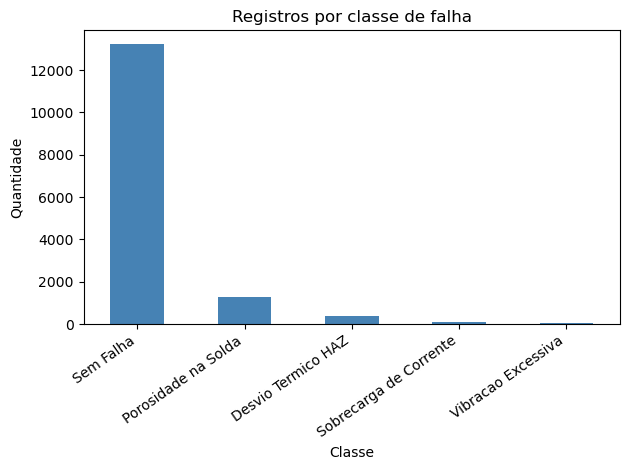

In [7]:
dados.classe_falha.value_counts().plot(kind="bar", color="steelblue")
plt.title("Registros por classe de falha")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


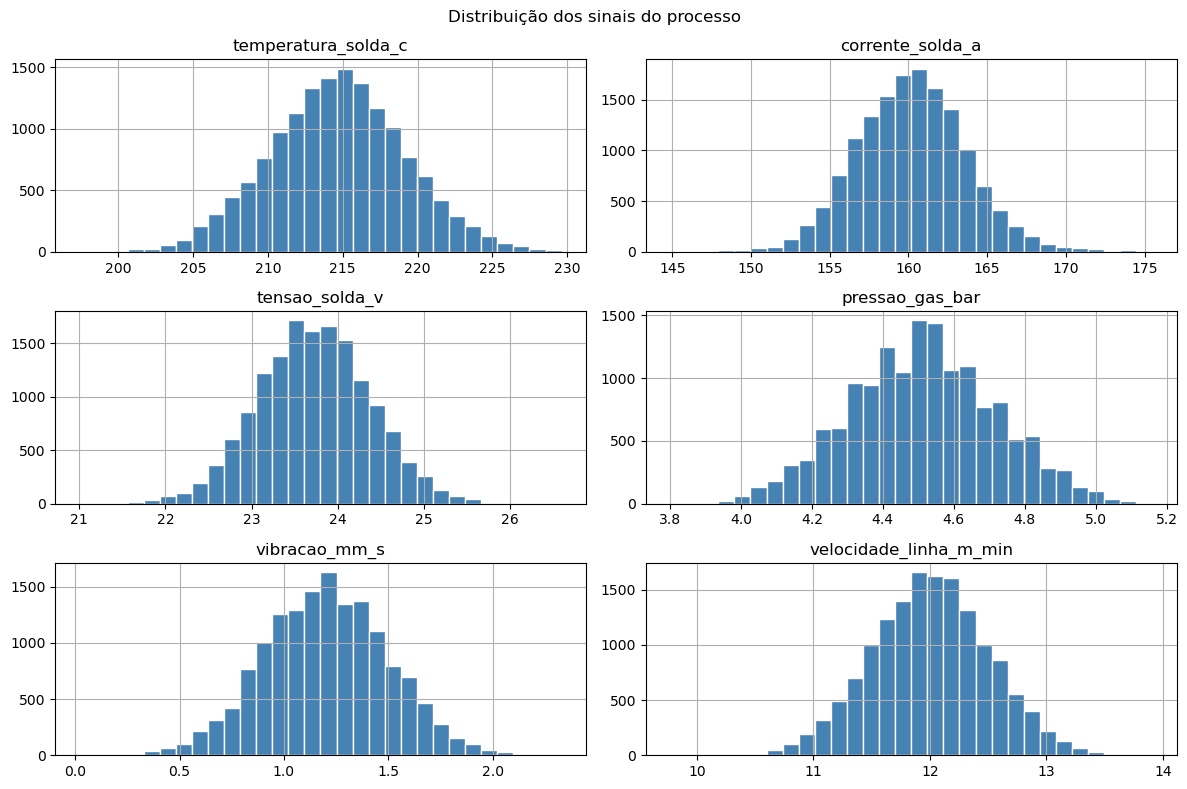

In [8]:
sensores = ["temperatura_solda_c", "corrente_solda_a", "tensao_solda_v",
            "pressao_gas_bar", "vibracao_mm_s", "velocidade_linha_m_min"]
dados[sensores].hist(figsize=(12, 8), bins=30, color="steelblue", edgecolor="white")
plt.suptitle("Distribuição dos sinais do processo")
plt.tight_layout()
plt.show()


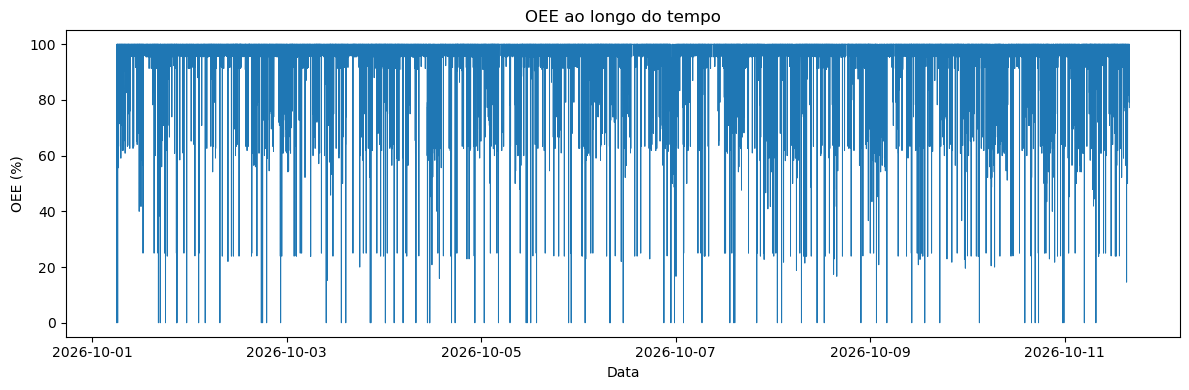

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(dados.timestamp, dados.oee_pct, linewidth=0.7)
plt.title("OEE ao longo do tempo")
plt.xlabel("Data")
plt.ylabel("OEE (%)")
plt.tight_layout()
plt.show()


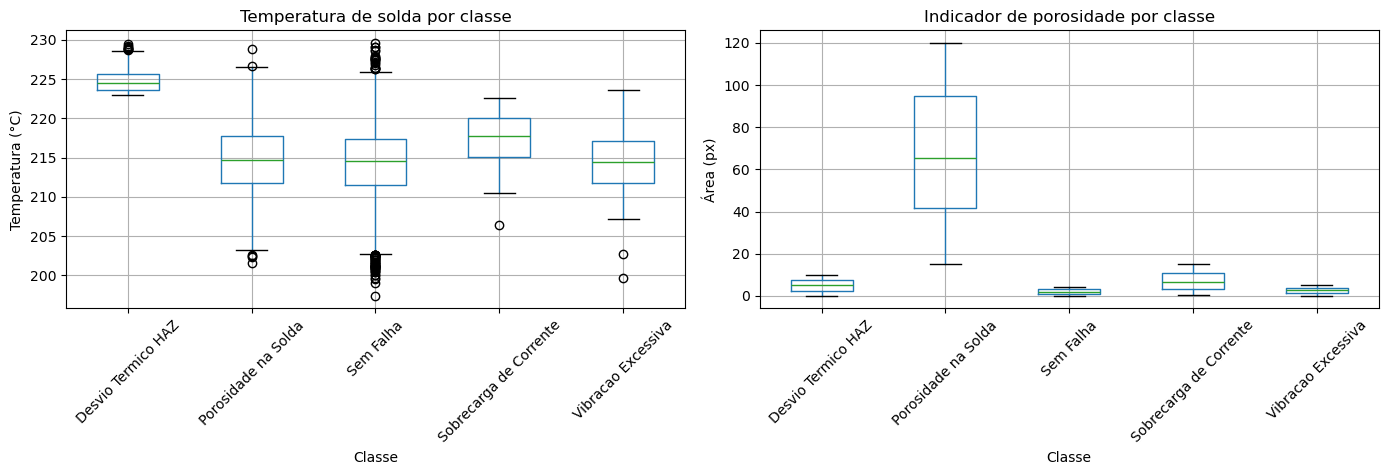

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
dados.boxplot(column="temperatura_solda_c", by="classe_falha", ax=eixos[0], rot=45)
eixos[0].set_title("Temperatura de solda por classe")
eixos[0].set_xlabel("Classe")
eixos[0].set_ylabel("Temperatura (°C)")
dados.boxplot(column="area_porosidade_px", by="classe_falha", ax=eixos[1], rot=45)
eixos[1].set_title("Indicador de porosidade por classe")
eixos[1].set_xlabel("Classe")
eixos[1].set_ylabel("Área (px)")
plt.suptitle("")
plt.tight_layout()
plt.show()


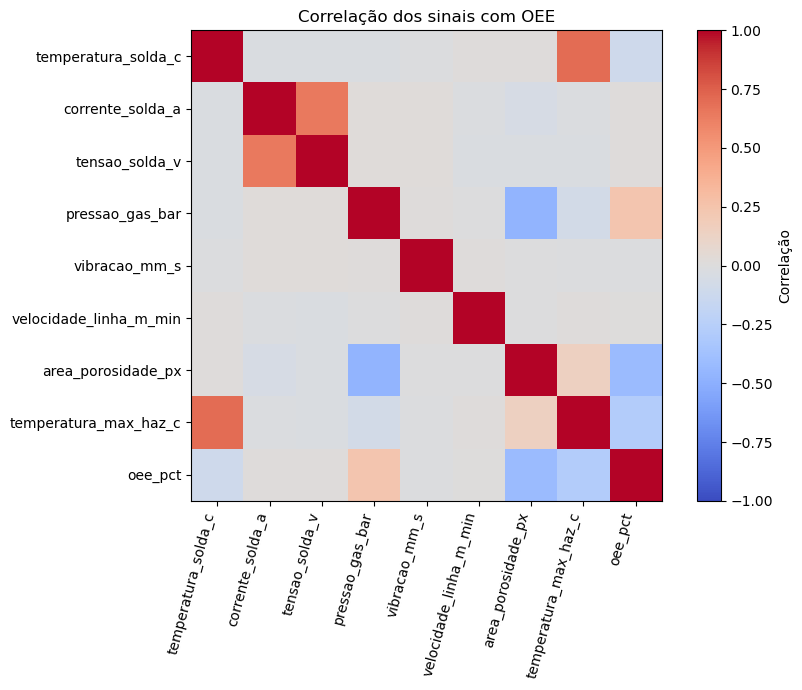

In [11]:
features = ["temperatura_solda_c", "corrente_solda_a", "tensao_solda_v",
            "pressao_gas_bar", "vibracao_mm_s", "velocidade_linha_m_min",
            "area_porosidade_px", "temperatura_max_haz_c"]
correlacao = dados[features + ["oee_pct"]].corr()
plt.figure(figsize=(9, 7))
plt.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlação")
plt.xticks(range(len(correlacao.columns)), correlacao.columns, rotation=75, ha="right")
plt.yticks(range(len(correlacao.index)), correlacao.index)
plt.title("Correlação dos sinais com OEE")
plt.tight_layout()
plt.show()
